# Electrodynamics from Scratch — Lecture 11: The Retarded Potentials

In electrostatics and magnetostatics we quietly assumed that fields respond *instantly* to their sources. In this lecture that assumption is dropped. If a charge at position $\mathbf{r}'$ changes its state at time $t'$, an observer at $\mathbf{r}$ cannot know about it until a light signal has had time to cross the separation $R = |\mathbf{r} - \mathbf{r}'|$. The state of the source that matters at time $t$ is therefore the state at the **retarded time**

$$
\tau \;=\; t \; -\; \frac{|\mathbf{r} - \mathbf{r}'|}{c},
$$

which is simply Newtonian causality written as an equation: the cause ($\tau$) must precede the effect ($t$) by exactly the light-travel time across $R$.

Solving Maxwell's equations with this causality requirement gives the **Liénard–Wiechert potentials** of a point charge $q$ moving with velocity $\mathbf{v}$, evaluated at the retarded position:

$$
\phi(\mathbf{r}, t) \;=\; \frac{1}{4\pi\varepsilon_0}\, \frac{q}{\left(1 - \hat{\mathbf{n}}\cdot\mathbf{v}/c\right) R},
\qquad
\mathbf{A}(\mathbf{r}, t) \;=\; \frac{\mathbf{v}}{c^2}\, \phi(\mathbf{r}, t),
$$

where $\hat{\mathbf{n}} = (\mathbf{r} - \mathbf{r}'(\tau))/R$ and everything on the right-hand side is taken at $\tau$. The factor $(1 - \hat{\mathbf{n}}\cdot\mathbf{v}/c)$ in the denominator is what distinguishes these from the naive Coulomb and Lorentz expressions: the charge is effectively weighted by how fast it moves *toward* the observer. Differentiating these potentials (carefully — $\tau$ itself depends on position and time) yields the Liénard–Wiechert fields

$$
\mathbf{E} \;=\; \frac{q}{4\pi\varepsilon_0} \frac{1 - \beta^2}{R^2}\,(\hat{\mathbf{n}} - \boldsymbol{\beta})
\;+\; \frac{q}{4\pi\varepsilon_0}\, \frac{1}{cR}\,\Big[\hat{\mathbf{n}} \times \big((\hat{\mathbf{n}} - \boldsymbol{\beta}) \times \mathbf{a}\big)\Big],
\qquad
\mathbf{B} \;=\; \frac{1}{c}\, \hat{\mathbf{n}} \times \mathbf{E},
$$

with $\boldsymbol{\beta} = \mathbf{v}/c$. The first (velocity) term falls off as $1/R^2$ and reduces to the Coulomb field for $\mathbf{v}=0$; the second (acceleration) term falls off as $1/R$ and *is* the radiation field. In this notebook we build up the retarded time, the retarded potentials and both field terms numerically, and watch a signal arrive late.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import electrodynamics_from_scratch as eds

## 1. Retarded time as a function of distance

A source sits at the origin and flashes at $t = 0$. An observer at distance $R$ only sees the flash at $t = R/c$, so the retarded time $\tau = t - R/c$ (the time of the source state being observed) is *negative* and grows more negative with distance. With the real speed of light the delays are nanoseconds per metre — plotted below in ns.

(<Figure size 700x400 with 1 Axes>,
 <Axes: title={'center': '$\\tau = t - R/c$ at fixed $t = 0$ (light takes 3.3 ns per metre)'}, xlabel='observer distance R (m)', ylabel='retarded time $\\tau$ (ns)'>)

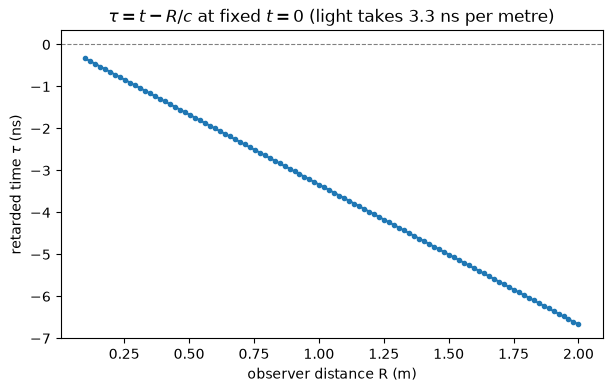

In [2]:
source = np.zeros(3)
x = np.linspace(0.1, 2.0, 100)                       # observer distances (m)
r_line = np.stack([x, np.zeros_like(x), np.zeros_like(x)], axis=1)

tau = eds.retarded_time(0.0, r_line, source)         # [N] retarded times at t = 0

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, tau * 1e9, 'o-', ms=3)
ax.axhline(0.0, color='gray', lw=0.8, ls='--')
ax.set_xlabel('observer distance R (m)')
ax.set_ylabel(r'retarded time $\tau$ (ns)')
ax.set_title(r'$\tau = t - R/c$ at fixed $t = 0$ (light takes 3.3 ns per metre)')
fig, ax

## 2. The scalar potential of an oscillating charge, evaluated at the retarded position

Let a charge $q$ oscillate *along the line of sight*: $\mathbf{r}'(t) = A\sin(\omega t)\,\hat{\mathbf{x}}$ with $A = 1$ cm and $f = 100$ MHz, observed at points on the $x$-axis. At a fixed observation time $t$, each field point needs the source state at its *own* retarded time $\tau = t - |\mathbf{r} - \mathbf{r}'(\tau)|/c$, which we find by fixed-point iteration (cheap, since $A \ll R$). We then call `eds.lieard_wiechert_potentials` with the retarded position and velocity: because the velocity points along $\hat{\mathbf{n}}$, the factor $(1 - \hat{\mathbf{n}}\cdot\mathbf{v}/c)$ visibly boosts the potential when the charge approaches and suppresses it when it recedes, relative to the static Coulomb curve.

(<Figure size 700x400 with 1 Axes>,
 <Axes: title={'center': 'scalar potential along the line of sight at $t = 0$'}, xlabel='x (m)', ylabel='$\\phi$ (V)'>)

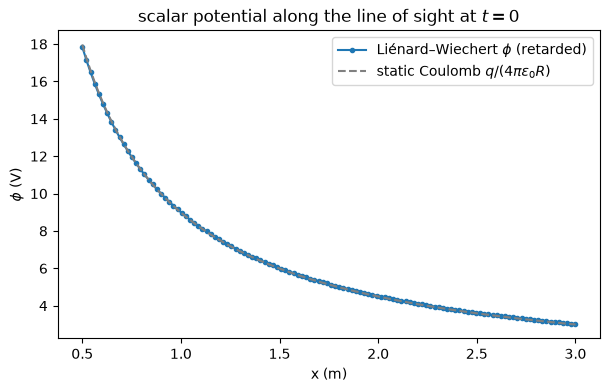

In [3]:
A, omega = 0.01, 2 * np.pi * 1e8        # amplitude (m), angular frequency (rad/s)
q = 1e-9                                # 1 nC

def source_pos(t):
    return np.array([A * np.sin(omega * t), 0.0, 0.0])

def source_vel(t):
    return np.array([A * omega * np.cos(omega * t), 0.0, 0.0])

def retarded_state(r_pts, t, n_iter=6):
    """Solve tau = t - |r - r'(tau)|/c by fixed-point iteration."""
    tau = t - np.linalg.norm(r_pts, axis=1) / eds.C_LIGHT
    for _ in range(n_iter):
        rp = np.stack([source_pos(tt) for tt in tau])
        tau = t - np.linalg.norm(r_pts - rp, axis=1) / eds.C_LIGHT
    rp = np.stack([source_pos(tt) for tt in tau])
    vp = np.stack([source_vel(tt) for tt in tau])
    return rp, vp, tau

x_obs = np.linspace(0.5, 3.0, 120)
r_obs = np.stack([x_obs, np.zeros_like(x_obs), np.zeros_like(x_obs)], axis=1)
rp, vp, tau_arr = retarded_state(r_obs, 0.0)

phi, A_vec = eds.lieard_wiechert_potentials(q, rp[0], vp[0], r_obs, 0.0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x_obs, phi, 'o-', ms=3, label=r'Liénard–Wiechert $\phi$ (retarded)')
ax.plot(x_obs, eds.K_COULOMB * q / x_obs, '--', color='gray',
        label=r'static Coulomb $q/(4\pi\varepsilon_0 R)$')
ax.set_xlabel('x (m)')
ax.set_ylabel(r'$\phi$ (V)')
ax.set_title('scalar potential along the line of sight at $t = 0$')
ax.legend()
fig, ax

## 3. A delayed signal: potential versus time at a fixed observer

Now sit at $\mathbf{r} = (2, 0, 0)$ m and sweep $t$ over one oscillation period. The observed potential $\phi(t)$ is built from the source state at $\tau = t - R/c$, so the oscillation arrives **delayed** by about $R/c \approx 6.7$ ns (a phase lag of $\omega R/c \approx 4.2$ rad) compared with the instantaneous potential $\phi_{\rm inst}(t) = q/(4\pi\varepsilon_0 |\mathbf{r} - \mathbf{r}'(t)|)$. The observed curve is also *amplified*: the Liénard–Wiechert denominator $(1 - \hat{\mathbf{n}}\cdot\mathbf{v}/c)$ weights the moments when the charge moves toward the observer.

light-travel delay R/c = 6.67 ns


(<Figure size 700x400 with 1 Axes>,
 <Axes: title={'center': 'the signal arrives late: potential at a fixed observer'}, xlabel='t (ns)', ylabel='$\\phi$ (V)'>)

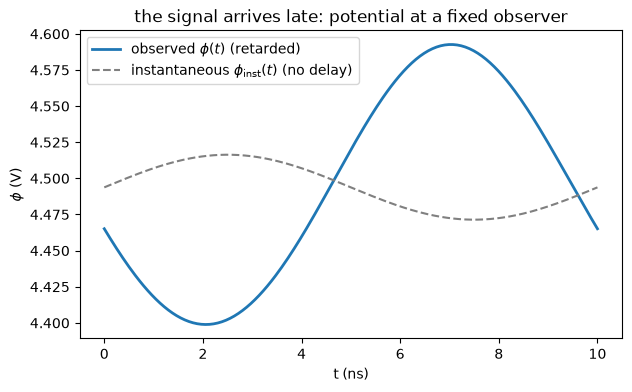

In [4]:
r_fix = np.array([[2.0, 0.0, 0.0]])
T = 2 * np.pi / omega
t_grid = np.linspace(0.0, T, 240)

phi_t = np.empty_like(t_grid)
phi_inst = np.empty_like(t_grid)
for i, tt in enumerate(t_grid):
    rp, vp, _ = retarded_state(r_fix, tt)
    phi_t[i] = eds.lieard_wiechert_potentials(q, rp[0], vp[0], r_fix, tt)[0][0]
    phi_inst[i] = eds.K_COULOMB * q / np.linalg.norm(r_fix[0] - source_pos(tt))

print(f'light-travel delay R/c = {2.0 / eds.C_LIGHT * 1e9:.2f} ns')
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t_grid * 1e9, phi_t, lw=2, label=r'observed $\phi(t)$ (retarded)')
ax.plot(t_grid * 1e9, phi_inst, '--', color='gray',
        label=r'instantaneous $\phi_{\rm inst}(t)$ (no delay)')
ax.set_xlabel('t (ns)')
ax.set_ylabel(r'$\phi$ (V)')
ax.set_title('the signal arrives late: potential at a fixed observer')
ax.legend()
fig, ax

## 4. The field of a uniformly moving charge

For $\mathbf{a} = 0$ the Liénard–Wiechert field is purely the velocity term, $\mathbf{E} = \frac{q}{4\pi\varepsilon_0}\frac{1-\beta^2}{R^2}(\hat{\mathbf{n}} - \boldsymbol{\beta})$, with $\mathbf{B} = \hat{\mathbf{n}}\times\mathbf{E}/c$. We take a charge moving along $x$ at $\beta = 0.5$ and evaluate $\mathbf{E}$ along a line on the axis of motion: the field still falls off as $1/R^2$ (a power-law fit recovers exponent $\approx -2$), and the vector relation $\mathbf{B} = \hat{\mathbf{n}}\times\mathbf{E}/c$ holds exactly. (On the axis itself $\hat{\mathbf{n}} \parallel \mathbf{E}$, so $\mathbf{B}$ vanishes there.)

power-law fit of |E| vs R: exponent = -2.000 (theory: -2)
max |B - (n x E)/c| = 0.000e+00 T   (B = n x E / c exactly)


(<Figure size 700x400 with 1 Axes>,
 <Axes: title={'center': 'uniform motion, $\\beta = 0.5$: the velocity term falls as $1/R^2$'}, xlabel='R (m)', ylabel='|E| (V/m)'>)

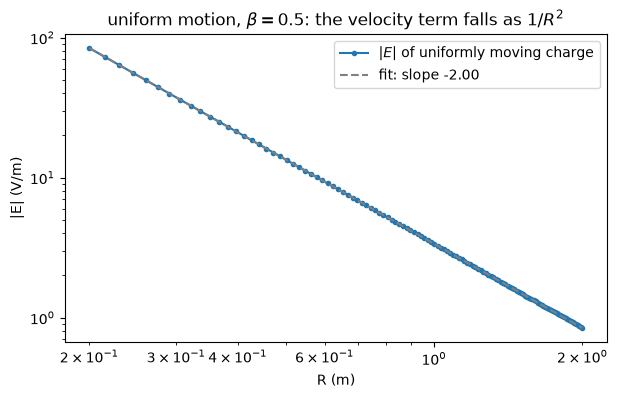

In [5]:
beta = 0.5
v = beta * eds.C_LIGHT
x_f = np.linspace(0.2, 2.0, 120)
r_f = np.stack([x_f, np.zeros_like(x_f), np.zeros_like(x_f)], axis=1)

E, B = eds.lieard_wiechert_fields(q, np.zeros(3), np.array([v, 0.0, 0.0]),
                                  np.zeros(3), r_f)
E_mag = np.linalg.norm(E, axis=1)
amp, expo = eds.power_law_fit(x_f, E_mag)
print(f'power-law fit of |E| vs R: exponent = {expo:.3f} (theory: -2)')

n_hat = (r_f - np.zeros(3)) / np.linalg.norm(r_f, axis=1)[:, None]
resid = np.max(np.abs(B - np.cross(n_hat, E) / eds.C_LIGHT))
print(f'max |B - (n x E)/c| = {resid:.3e} T   (B = n x E / c exactly)')

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(x_f, E_mag, 'o-', ms=3, label=r'$|E|$ of uniformly moving charge')
ax.loglog(x_f, amp * x_f**expo, '--', color='gray', label=f'fit: slope {expo:.2f}')
ax.set_xlabel('R (m)')
ax.set_ylabel('|E| (V/m)')
ax.set_title(r'uniform motion, $\beta = 0.5$: the velocity term falls as $1/R^2$')
ax.legend()
fig, ax

## 5. Field lines: moving charge versus static charge

The factor $(1 - \beta^2)$ in the velocity term makes the field of a moving charge anisotropic: it is *weakened along* the direction of motion and (relatively) *strengthened transverse* to it. The streamplots below compare $\beta = 0.5$ with the static Coulomb case; the moving-charge pattern is visibly flattened toward the plane transverse to the motion. (The single grid point exactly at the charge is nudged aside to avoid the singular point.)

(<Figure size 1200x500 with 2 Axes>,
 <Axes: title={'center': 'moving charge, $\\beta = 0.5$'}, xlabel='x (m)', ylabel='y (m)'>)

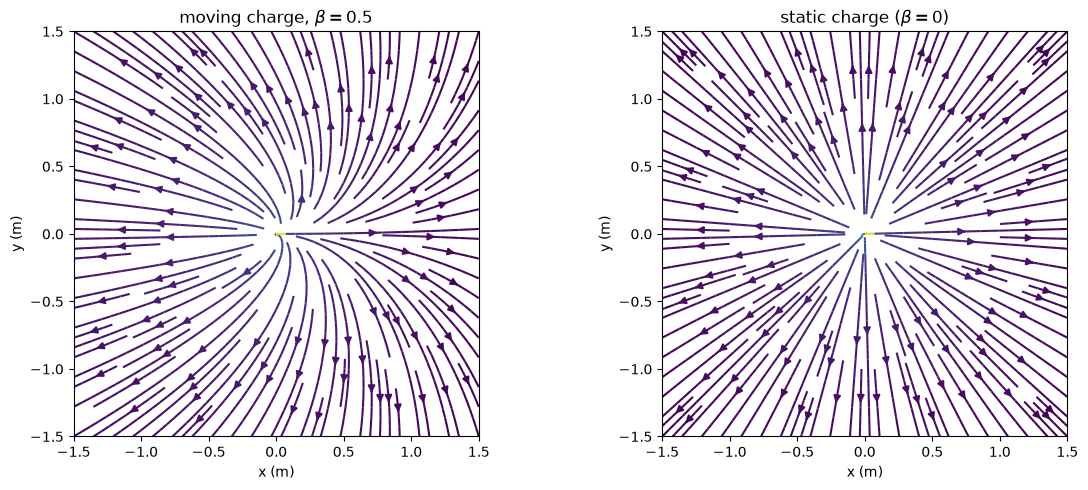

In [6]:
def moving_field_func(v_vec):
    """field_func(x, y) -> (Ex, Ey) for a charge at the origin moving along x."""
    def field_func(x, y):
        pts = np.stack([x.ravel(), y.ravel(), np.zeros(x.size)], axis=1)
        R = np.linalg.norm(pts, axis=1)
        pts = pts.copy()
        pts[R < 1e-6] = [1e-6, 0.0, 0.0]   # nudge the singular point aside
        E, _ = eds.lieard_wiechert_fields(q, np.zeros(3), v_vec, np.zeros(3), pts)
        return E[:, 0].reshape(x.shape), E[:, 1].reshape(x.shape)
    return field_func

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
eds.plot_field_lines(moving_field_func(np.array([v, 0.0, 0.0])),
                     extent=1.5, ax=ax1, title=r'moving charge, $\beta = 0.5$')
eds.plot_field_lines(moving_field_func(np.zeros(3)),
                     extent=1.5, ax=ax2, title=r'static charge ($\beta = 0$)')
fig.tight_layout()
fig, ax1

## 6. Splitting the field: velocity ($1/R^2$) versus acceleration ($1/R$) terms

Give the charge an acceleration along its motion and observe on a line *transverse* to it (where the radiation term $[\hat{\mathbf{n}} \times ((\hat{\mathbf{n}} - \boldsymbol{\beta}) \times \mathbf{a})]$ is maximal). `eds.lieard_wiechert_fields` returns the total field; calling it again with $\mathbf{a}=0$ isolates the velocity term, and `eds.split_velocity_acceleration` performs the subtraction $\mathbf{E}_{\rm rad} = \mathbf{E}_{\rm total} - \mathbf{E}_{\rm velocity}$. Power-law fits then show the two signatures — the velocity term decays as $1/R^2$, the radiation term only as $1/R$ — so radiation overtakes the near field beyond $R \approx c(1-\beta^2)/a$, here about $8$ m.

In [ ]:
a_vec = np.array([0.1 * eds.C_LIGHT, 0.0, 0.0])
y_f = np.linspace(0.2, 20.0, 120)
r_y = np.stack([np.zeros_like(y_f), y_f, np.zeros_like(y_f)], axis=1)

E_tot, B_tot = eds.lieard_wiechert_fields(q, np.zeros(3),
                                          np.array([v, 0.0, 0.0]), a_vec, r_y)
E_v0, _ = eds.lieard_wiechert_fields(q, np.zeros(3),
                                     np.array([v, 0.0, 0.0]), np.zeros(3), r_y)
E_vel, E_rad = eds.split_velocity_acceleration(E_tot, E_v0)
vel_mag = np.linalg.norm(E_vel, axis=1)
rad_mag = np.linalg.norm(E_rad, axis=1)

amp_v, expo_v = eds.power_law_fit(y_f, vel_mag)
amp_r, expo_r = eds.power_law_fit(y_f, rad_mag)
print(f'velocity term:     exponent = {expo_v:.3f} (theory: -2)')
print(f'acceleration term: exponent = {expo_r:.3f} (theory: -1)')

idx = np.argmin(np.abs(rad_mag / vel_mag - 1.0))
cross_theory = eds.C_LIGHT * (1 - beta**2) * np.sqrt(1 + beta**2) / np.linalg.norm(a_vec)
print(f'crossover |E_rad| = |E_vel| at R ~ {y_f[idx]:.2f} m '
      f'(theory c(1-beta^2)*sqrt(1+beta^2)/a ~ {cross_theory:.1f} m)')

fig, ax = eds.plot_decay(
    y_f,
    {r'velocity $\propto 1/R^2$': vel_mag,
     r'radiation $\propto 1/R$': rad_mag},
    title='Liénard–Wiechert field split: near (velocity) vs radiation (acceleration)',
)
ax.set_xlabel('R (m)')
fig, ax

## Exercises

1. **Causality check.** Using `eds.retarded_time`, compute the retarded time at $t = 1\,\mu{\rm s}$ for observers at $R = 10, 100, 1000$ m from a source at the origin. Verify by hand that $\tau = t - R/c$ in each case, and explain in one sentence why $\tau$ must always be *earlier* than $t$.

2. **Delay versus frequency.** In Section 3, the observed oscillation lags the instantaneous one by the phase $\omega R/c$. Using the fixed-point-iteration helper from Section 2, plot the observed $\phi(t)$ at $R = 2$ m for $f = 10$ MHz, $100$ MHz and $1$ GHz on the same axes. At which frequency is the lag easiest to see, and why?

3. **Vector potential.** In Section 2, `eds.lieard_wiechert_potentials` also returns $\mathbf{A}$. Verify numerically that $\mathbf{A} = \mathbf{v}(\tau)\,\phi / c^2$ at every point on the line, and state which of Maxwell's equations forces this relation between $\phi$ and $\mathbf{A}$.

4. **Anisotropy of the velocity field.** In Section 5, evaluate `eds.lieard_wiechert_fields` with $\mathbf{a}=0$ at two fixed distances $R = 1$ m, one directly ahead of the moving charge (along $x$) and one transverse to it (along $y$). Compute the ratio $|E_{\rm transverse}|/|E_{\rm longitudinal}|$ for $\beta = 0$, $0.5$ and $0.9$ and compare with the theoretical factor $(1-\beta^2)^{-1}$.

5. **Radiation takeover.** In Section 6, find (numerically) the distance at which the radiation term overtakes the velocity term, i.e. where $|E_{\rm rad}| = |E_{\rm vel}|$, using `eds.lieard_wiechert_fields` and `eds.split_velocity_acceleration`. How does this crossover distance scale with the acceleration magnitude? Confirm by re-running with a ten-times larger $\mathbf{a}$.

6. **Conceptual: why radiation?** The acceleration term carries energy to infinity because it falls off as $1/R$, while the velocity term falls off as $1/R^2$. In terms of the Poynting vector $\mathbf{S} = (1/\mu_0)\,\mathbf{E}\times\mathbf{B}$ and the area $4\pi R^2$ of a sphere, explain in two or three sentences why only the $1/R$ term contributes to a finite radiated power, and use `eds.larmor_power` to compute the power radiated by the charge in Section 6.
